# Mathematic Topics toward Machine Learning

This notebook covers three mathematical foundations for machine learning: **stochastic processes** (random walks, Markov chains, MCMC), **information theory and structured probabilistic models** (entropy, KL divergence, graphical models), and **numerical computation** (stability, gradients, curvature, and optimization).

**Main textbooks**

- Michael J. Evans and Jeffrey S. Rosenthal, *Probability and Statistics: The Science of Uncertainty* — Chapter 11, §§11.1–11.3.
- Ian Goodfellow, Yoshua Bengio, and Aaron Courville, *Deep Learning* — §§3.13–3.14 and Chapter 4, primarily §§4.1–4.4.

Unless noted otherwise, logarithms are natural ($\log=\ln$). The executable examples use NumPy and Matplotlib.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
SEED = 20261024
rng = np.random.default_rng(SEED)
print('NumPy version:', np.__version__)

NumPy version: 1.21.5


---
# Part I — Stochastic Processes

*Evans and Rosenthal, Chapter 11, §§11.1–11.3*

## From transition rules to long-run behavior

A stochastic process is a family of random variables indexed by time, $(X_t)_{t\ge0}$. Its individual values are random, but the rules governing their evolution may be mathematically precise. In Chapter 11 of Evans and Rosenthal, the random walk provides the simplest example; Markov chains generalize the one-step transition rule; MCMC then turns such rules into computational tools for distributions that are difficult to sample directly.

The distinction between **the state at time $t$**, **the distribution of that state**, and **the long-run empirical frequency of states** will be useful throughout this part.

## 1. Random walks and gambler's ruin

Let $Z_1,Z_2,\ldots$ be independent, identically distributed increments with

$$
\Pr(Z_k=+1)=p,\qquad \Pr(Z_k=-1)=q=1-p.
$$

A simple random walk with initial fortune $X_0=a$ is

$$
\boxed{X_n=a+\sum_{k=1}^{n}Z_k.}
$$

Since $\mathbb E[Z_k]=p-q=2p-1$ and $\mathrm{Var}(Z_k)=1-(2p-1)^2=4pq$,

$$
\mathbb E[X_n]=a+n(2p-1),\qquad
\mathrm{Var}(X_n)=4npq.
$$

The first expression describes **drift**: an unbiased walk ($p=1/2$) has constant expected fortune, whereas $p>1/2$ and $p<1/2$ give positive and negative drift. The second describes uncertainty around that expectation. In particular, $\mathbb E[X_n]=a$ does **not** mean an individual fair walk stays near $a$: its variance grows with $n$.

This is an unconstrained walk. A gambler's ruin process adds a stopping rule at a boundary, so the same increments now answer a different question: *Which boundary will be reached first?*

### Absorbing boundaries: derive hitting probabilities rather than guessing from drift

Let the walk start from $a\in\{1,\ldots,c-1\}$ and stop when it first reaches $0$ or $c$. Denote the first hitting time of $b$ by $\tau_b$ and define

$$
u_a=\Pr(\tau_c<\tau_0\mid X_0=a).
$$

Condition on the very first step. If the walk moves up, the success probability becomes $u_{a+1}$; if it moves down, it becomes $u_{a-1}$. Therefore

$$
\boxed{u_a=pu_{a+1}+qu_{a-1},\qquad u_0=0,\quad u_c=1.}
$$

For $p\ne q$, a trial solution $u_a=r^a$ produces $pr^2-r+q=0$ with roots $1$ and $q/p$. The general solution $A+B(q/p)^a$ then gives

$$
\boxed{
\Pr(\tau_c<\tau_0\mid X_0=a)
=\begin{cases}
\dfrac{a}{c},&p=\tfrac12,\\[6pt]
\dfrac{1-(q/p)^a}{1-(q/p)^c},&p\ne\tfrac12.
\end{cases}}
$$

The fair case is obtained separately from the affine solution (or by a limit). This is the probability of reaching the **upper target before ruin**, not the probability of eventual ruin without an upper boundary.

If the upper boundary is removed, a different limiting argument gives

$$
\boxed{\Pr(\tau_0<\infty\mid X_0=a)=
\begin{cases}
1,&p\le\tfrac12,\\
(q/p)^a,&p>\tfrac12.
\end{cases}}
$$

A positive drift does not make ruin impossible; it makes it less likely. In betting systems that double stakes after losses, the assumption of unlimited funds and no betting limit is crucial: an appealing expected-value argument does not defeat a finite bankroll constraint.

### Experiment 1 — A small change in $p$ can have a large long-run effect

We compare theoretical eventual ruin probabilities, finite-boundary theory, and a Monte Carlo estimate for the finite-boundary problem. The simulation terminates only when the path reaches 0 or $c$, so it matches the finite-boundary event precisely.

In [2]:
def reach_upper_prob(a, c, p):
    q = 1.0 - p
    if np.isclose(p, 0.5):
        return a / c
    r = q / p
    return (1.0 - r**a) / (1.0 - r**c)

def finite_ruin_sim(a=5, c=20, p=0.5, trials=2500, rng=None):
    rng = np.random.default_rng() if rng is None else rng
    x = np.full(trials, a, dtype=int)
    moving = (x > 0) & (x < c)
    while np.any(moving):
        idx = np.flatnonzero(moving)
        x[idx] += np.where(rng.random(len(idx)) < p, 1, -1)
        moving = (x > 0) & (x < c)
    return np.mean(x == 0)

for p in [0.48, 0.50, 0.52, 0.55]:
    finite_theory = 1 - reach_upper_prob(5, 20, p)
    estimate = finite_ruin_sim(5, 20, p, 3000, rng)
    infinite_ruin = 1.0 if p <= 0.5 else ((1-p)/p)**5
    print(f'p={p:.2f} | finite ruin: theory={finite_theory:.3f}, '
          f'MC={estimate:.3f} | infinite-upper-limit ruin={infinite_ruin:.3f}')

p=0.48 | finite ruin: theory=0.876, MC=0.882 | infinite-upper-limit ruin=1.000
p=0.50 | finite ruin: theory=0.750, MC=0.747 | infinite-upper-limit ruin=1.000
p=0.52 | finite ruin: theory=0.587, MC=0.588 | infinite-upper-limit ruin=0.670
p=0.55 | finite ruin: theory=0.355, MC=0.357 | infinite-upper-limit ruin=0.367


The simulated probability approaches the corresponding **finite-boundary** theoretical probability as we increase the number of independent trials. The same experiment also makes clear why one must not interchange two different events: *ruin before reaching $c$* versus *ever reaching zero without any upper stopping boundary*. The pronounced sensitivity to $p$ is a feature of repeated stochastic decisions, not evidence that a slightly favorable game has no risk.

## 2. Markov chains 

A **time-homogeneous, discrete-state Markov chain** is a sequence $(X_n)$ for which the conditional law of the next state depends on the present state but not on the earlier history:

$$
\Pr(X_{n+1}=j\mid X_n=i,X_{n-1},\ldots,X_0)
=\Pr(X_{n+1}=j\mid X_n=i)=P_{ij}.
$$

The matrix $P\in\mathbb R^{m\times m}$ of transition probabilities is **row-stochastic**: $P_{ij}\ge0$ and $\sum_jP_{ij}=1$ for every $i$. The Markov property does **not** assert that $X_n$ and $X_{n+1}$ are independent; it says only that earlier states add no predictive information once $X_n$ is known.

If $v_0\in\mathbb R^{1\times m}$ is the row vector of initial state probabilities, the total-probability rule gives

$$
(v_1)_j=\sum_i(v_0)_iP_{ij},\qquad
\boxed{v_n=v_0P^n.}
$$

A **stationary distribution** is a probability row vector $\pi$ satisfying

$$
\pi P=\pi,\qquad\sum_i\pi_i=1,\qquad\pi_i\ge0.
$$

The equality means that **starting in $\pi$ leaves the one-time marginal distribution unchanged**. This definition alone is not a promise that $v_0P^n\to\pi$ for every $v_0$. Convergence needs additional assumptions.

### A two-state chain: distributions, eigenvectors, and equilibrium

Consider the two-state transition matrix

$$
P=\begin{pmatrix}0.1&0.9\\0.6&0.4\end{pmatrix},
\qquad \pi=(0.4,0.6).
$$

Indeed $\pi P=\pi$. If the chain starts in state 0, $v_0=(1,0)$ and the subsequent distributions are $(1,0)P^n$; they approach $\pi$ in this example.

It is helpful to see how this fits linear algebra. Stationarity is a **left eigenvector equation with eigenvalue $1$**. Other eigenvalues control how deviations evolve. Here the second eigenvalue is $-0.5$, so deviations from equilibrium alternate in sign while shrinking in magnitude. This gives a geometric explanation for the oscillating approach seen in the plot below.

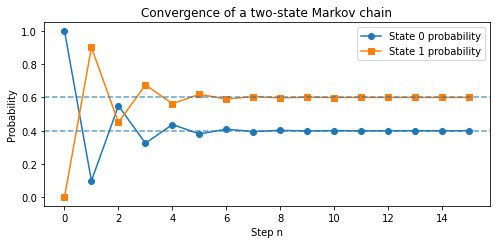

In [3]:
P = np.array([[0.1, 0.9], [0.6, 0.4]])
pi = np.array([0.4, 0.6])
v = np.array([1.0, 0.0])
trajectory = [v.copy()]
for _ in range(15):
    v = v @ P
    trajectory.append(v.copy())
trajectory = np.array(trajectory)
assert np.allclose(pi @ P, pi)

plt.figure(figsize=(7, 3.5))
plt.plot(trajectory[:, 0], 'o-', label='State 0 probability')
plt.plot(trajectory[:, 1], 's-', label='State 1 probability')
plt.axhline(pi[0], linestyle='--', alpha=0.7)
plt.axhline(pi[1], linestyle='--', alpha=0.7)
plt.xlabel('Step n')
plt.ylabel('Probability')
plt.title('Convergence of a two-state Markov chain')
plt.legend()
plt.tight_layout()
plt.show()

### Detailed balance, reversibility, and the missing condition for convergence

The **detailed-balance condition** is

$$
\boxed{\pi_iP_{ij}=\pi_jP_{ji}\quad\text{for every pair }i,j.}
$$

It equates the probability flux from $i$ to $j$ with the flux in the reverse direction. Summing over $i$ gives

$$
(\pi P)_j=\sum_i\pi_iP_{ij}=\sum_i\pi_jP_{ji}
=\pi_j\sum_iP_{ji}=\pi_j,
$$

where the final sum uses the fact that **row $j$** of $P$ sums to one. Thus detailed balance implies stationarity. A chain satisfying it is **reversible** with respect to $\pi$. Stationarity does not imply reversibility.

For a finite-state chain, **irreducibility** (states communicate) and **aperiodicity** (no forced cyclic schedule) ensure convergence toward the unique stationary distribution. A counterexample to the naive 'stationary means limiting' interpretation is

$$
P=\begin{pmatrix}0&1\\1&0\end{pmatrix},\qquad\pi=(1/2,1/2).
$$

This chain alternates between states 0 and 1. Its stationary distribution exists, but a chain starting from a fixed state never converges to it at a single time step.

**Ehrenfest urn.** With $d$ particles, select one uniformly and move it to the other urn. If $i$ counts particles in the first urn,

$$
P_{i,i+1}=\frac{d-i}{d},\qquad
P_{i,i-1}=\frac{i}{d},\qquad
\boxed{\pi_i=\binom di2^{-d}}.
$$

Detailed balance is verified via $\pi_i(d-i)/d=\pi_{i+1}(i+1)/d$. The urn process changes the parity of $i$ at every step, so it is periodic in its unmodified form. This provides a concrete distinction between a stationary distribution and convergence in distribution.

In [4]:
from math import comb

def ehrenfest_transition(d):
    M = np.zeros((d + 1, d + 1))
    for i in range(d + 1):
        if i < d:
            M[i, i + 1] = (d - i) / d
        if i > 0:
            M[i, i - 1] = i / d
    return M

d = 8
Pe = ehrenfest_transition(d)
pie = np.array([comb(d, i)/2**d for i in range(d+1)])
print('Rows sum to 1:', np.allclose(Pe.sum(axis=1), 1))
print('Stationary:', np.allclose(pie @ Pe, pie))
print('Detailed balance:', np.allclose(pie[:, None]*Pe, pie[None, :]*Pe.T))
print('Ehrenfest stationary distribution:', pie)

Rows sum to 1: True
Stationary: True
Detailed balance: True
Ehrenfest stationary distribution: [0.0039 0.0312 0.1094 0.2188 0.2734 0.2188 0.1094 0.0312 0.0039]


## 3. Markov Chain Monte Carlo 

The preceding section described what happens when a transition matrix is applied repeatedly. **MCMC reverses the design problem:** choose transitions so that the chain's desired stationary distribution is a target $\pi$. This is useful when we can evaluate an *unnormalized* density or mass $\widetilde\pi(x)$, but cannot easily draw independent exact samples from $\pi$.

For a test function $h$, we seek

$$
\mu=\mathbb E_\pi[h(X)],\qquad
\widehat\mu_N=\frac1N\sum_{t=1}^Nh(X_t).
$$

Under appropriate ergodicity and integrability assumptions, the **Markov-chain law of large numbers** gives $\widehat\mu_N\to\mu$. Unlike ordinary independent Monte Carlo, successive $X_t$ may be strongly correlated. Their marginal distribution may also depend on initialization for a substantial number of early iterations.

- **Burn-in** discards early iterates to limit initial-condition effects; it is not a proof that the remaining chain has converged.
- **Mixing** describes how quickly the chain approaches its equilibrium distribution.
- **Autocorrelation** determines how much new information each correlated draw contributes. For a stationary chain under suitable summability assumptions, $\mathrm{Var}(\widehat\mu_N)\approx\sigma_h^2\tau_{\mathrm{int}}/N$, where $\tau_{\mathrm{int}}=1+2\sum_{k\ge1}\rho_h(k)$; an effective sample-size heuristic is $N/\tau_{\mathrm{int}}$.
- **Diagnostics** (trace plots, autocorrelations, multiple chains) can reveal problems but cannot universally certify convergence.

This distinction—**correct asymptotic target versus finite-time computational quality**—becomes important when comparing MCMC with learned samplers.

### Metropolis–Hastings: use detailed balance to construct a chain

Suppose the chain is currently at state $i$. First propose a candidate $j$ using a **proposal distribution** $q_{ij}=\Pr(\text{propose }j\mid i)$. Then accept the proposal with probability

$$
\boxed{a(i,j)=\min\!\left(1,\frac{\pi_jq_{ji}}{\pi_iq_{ij}}\right)}
$$

when the ratio is well-defined; zero-support and unreachable states require the corresponding standard case handling. Rejected proposals leave the chain at $i$. For distinct states, the resulting transition is $P_{ij}=q_{ij}a(i,j)$ and

$$
\pi_iP_{ij}=\min(\pi_iq_{ij},\pi_jq_{ji})=\pi_jP_{ji}.
$$

Thus detailed balance ensures that $\pi$ is stationary. **It does not by itself establish irreducibility, aperiodicity, or rapid mixing.**

Most importantly, if $\pi_i=\widetilde\pi_i/Z$, the normalizing constant cancels:

$$
\frac{\pi_jq_{ji}}{\pi_iq_{ij}}
=\frac{\widetilde\pi_jq_{ji}}{\widetilde\pi_iq_{ij}}.
$$

For symmetric proposals $q_{ij}=q_{ji}$, the acceptance rule simplifies further to $\min(1,\widetilde\pi_j/\widetilde\pi_i)$. The algorithm thereby converts **relative probability scores** into a Markov chain with a specified stationary distribution.

### Experiment 2 — A discrete MH sampler

We construct a five-state target and use **independence proposals** (each state proposed uniformly), so $q_{ij}=q_{ji}$. The symmetric proposal simplifies the acceptance ratio and allows a direct comparison between empirical state frequencies and the specified target.

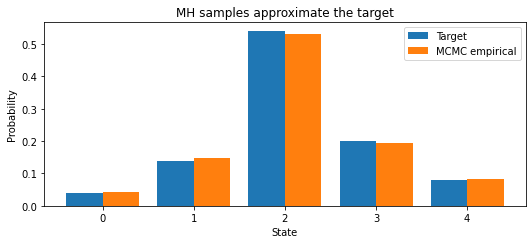

Acceptance rate: 0.561
Max absolute discrepancy: 0.009


In [5]:
target = np.array([0.04, 0.14, 0.54, 0.20, 0.08])
assert np.isclose(target.sum(), 1)

def metropolis_discrete(target, steps=20000, rng=None):
    rng = np.random.default_rng() if rng is None else rng
    x = 0
    trace = np.empty(steps, dtype=int)
    accepts = 0
    n = len(target)
    for t in range(steps):
        proposed = int(rng.integers(n))  # symmetric independence proposal
        a = min(1.0, target[proposed] / target[x])
        if rng.random() < a:
            x = proposed
            accepts += 1
        trace[t] = x
    return trace, accepts / steps

trace, acceptance_rate = metropolis_discrete(target, rng=rng)
burn_in = 1000
empirical = np.bincount(trace[burn_in:], minlength=len(target)) / len(trace[burn_in:])
fig, ax = plt.subplots(figsize=(7.5, 3.5))
idx = np.arange(len(target))
ax.bar(idx - 0.2, target, width=0.4, label='Target')
ax.bar(idx + 0.2, empirical, width=0.4, label='MCMC empirical')
ax.set(xticks=idx, xlabel='State', ylabel='Probability', title='MH samples approximate the target')
ax.legend()
plt.tight_layout()
plt.show()
print('Acceptance rate:', round(acceptance_rate, 3))
print('Max absolute discrepancy:', round(np.max(np.abs(empirical-target)), 4))

### Gibbs sampling: update coordinates using full conditional distributions

When each full conditional of a joint target $\pi(x_1,\ldots,x_d)$ is tractable, Gibbs sampling iterates through components. At coordinate $i$ in a systematic sweep, draw

$$
X_i^{(t+1)}\sim
\pi\!\left(x_i\mid X_1^{(t+1)},\ldots,X_{i-1}^{(t+1)},X_{i+1}^{(t)},\ldots,X_d^{(t)}\right).
$$

An exact draw from a full conditional does not need a subsequent accept/reject decision: this is sometimes expressed as **an MH acceptance probability of one**. The resulting coordinate-updating kernels preserve the target, although the output is generally neither independent nor well mixed.

As a transparent example, let $(X,Y)$ be bivariate normal with means zero, variances one, and correlation $|\rho|<1$. Completing the square gives

$$
X\mid Y=y\sim\mathcal N(\rho y,1-\rho^2),\qquad
Y\mid X=x\sim\mathcal N(\rho x,1-\rho^2).
$$

Large $|\rho|$ makes the coordinate-wise chain move slowly along a strongly correlated ridge: a correct stationary distribution does not imply efficient exploration. The code below demonstrates this.

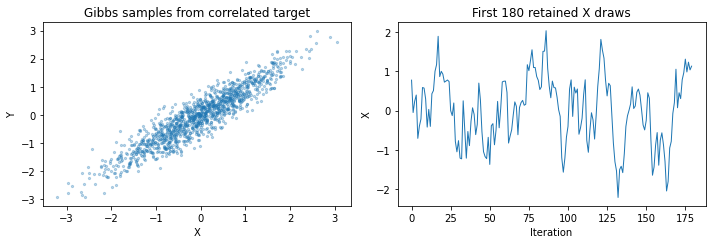

Estimated correlation: 0.928
Lag-1 autocorrelation of X: 0.859


In [6]:
def gibbs_bivariate_normal(rho=0.93, n=7000, rng=None):
    rng = np.random.default_rng() if rng is None else rng
    x, y = 0., 0.
    out = np.zeros((n, 2))
    sd = np.sqrt(1 - rho**2)
    for t in range(n):
        x = rho*y + sd*rng.normal()
        y = rho*x + sd*rng.normal()
        out[t] = (x, y)
    return out

gibbs = gibbs_bivariate_normal(rng=rng)[500:]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].scatter(gibbs[::5, 0], gibbs[::5, 1], s=5, alpha=0.3)
ax[0].set(title='Gibbs samples from correlated target', xlabel='X', ylabel='Y')
ax[1].plot(gibbs[:180, 0], lw=1)
ax[1].set(title='First 180 retained X draws', xlabel='Iteration', ylabel='X')
plt.tight_layout()
plt.show()
print('Estimated correlation:', round(np.corrcoef(gibbs.T)[0,1], 3))
print('Lag-1 autocorrelation of X:', round(np.corrcoef(gibbs[:-1,0], gibbs[1:,0])[0,1], 3))

### Interpreting MCMC experiments

The simulations above illustrate the practical tasks accompanying the Metropolis–Hastings and Gibbs methods. A convincing computational study compares empirical samples with known probabilities or moments while also checking sample dependence.

An MCMC experiment should specify the target distribution, initialization, proposal or full conditional, number of steps, any burn-in, and the method used to assess mixing. **Agreement with the target in one finite experiment is evidence, not a mathematical guarantee of convergence.**


## 4. Sampling and learned probabilistic models: what can neural networks replace?

After learning MCMC, a natural objection arises: if neural networks can fit complex probability distributions and generate samples, why retain a sequential sampling algorithm?

The premise hides **different computational tasks**. Given a specific distribution $\pi$—for example, a Bayesian posterior—MCMC attempts to produce samples whose long-run empirical behavior matches **that target**. A learned generative model instead fits a parameterized family, producing samples from its **learned approximation**. Both may be approximate in practice, but the sources of approximation differ.

| Approach | What is specified or learned? | Main limitation to keep in view |
|---|---|---|
| Metropolis–Hastings, Gibbs, HMC | A transition process targeting a specified distribution | Long-run correctness needs assumptions; finite-time bias and autocorrelation can be substantial. |
| Autoregressive models and normalizing flows | A tractable, directly samplable density model | Distributional accuracy depends on model family, data, and optimization. |
| Variational inference | A tractable approximation $q_\phi$ to a target posterior | Approximation bias depends on the family and optimization objective. |
| Neural energy-based models | An unnormalized score or energy for configurations | A score does not by itself give normalized probabilities or exact samples. |

The defensible conclusion is **not** that MCMC is mathematically irreplaceable, always computationally preferable, or guaranteed accurate in finite time. Rather, its distinctive advantage is the ability to target an **explicitly chosen distribution** with asymptotic guarantees when the conditions hold. Deep models and MCMC are often complementary; learned proposal distributions and MCMC-corrected samplers are examples.

### The partition function shows why 'learning a score' is not the same as learning normalized probabilities

An energy-based model assigns lower energies to preferred configurations:

$$
p_\theta(x)=\frac{e^{-E_\theta(x)}}{Z_\theta},\qquad
Z_\theta=\int e^{-E_\theta(x)}\,dx
$$

(the integral is a sum for discrete $x$). Its normalized log likelihood is

$$
\log p_\theta(x)=-E_\theta(x)-\log Z_\theta.
$$

The difficulty is not merely evaluating $E_\theta(x)$ but accounting for **all possible configurations** through $Z_\theta$. Assuming differentiation under the integral is legitimate,

$$
\begin{aligned}
\nabla_\theta\log Z_\theta
&=\frac{1}{Z_\theta}\int -e^{-E_\theta(x')}\nabla_\theta E_\theta(x')\,dx'\\
&=-\mathbb E_{X\sim p_\theta}[\nabla_\theta E_\theta(X)].
\end{aligned}
$$

Therefore

$$
\boxed{\nabla_\theta\log p_\theta(x)
=-\nabla_\theta E_\theta(x)
+\mathbb E_{X\sim p_\theta}[\nabla_\theta E_\theta(X)].}
$$

The first term changes the energy at the observed example; the second corrects the model using the distribution it currently assigns to other examples. **Omitting $\log Z_\theta$ does not preserve maximum-likelihood learning.** In fact, adding a parameter-dependent constant to every energy changes an unnormalized energy objective while leaving the normalized distribution unchanged; an objective that only lowers observed energies is consequently ill posed without an additional mechanism.

MCMC can approximate the model expectation without explicitly evaluating $Z_\theta$. This is one reason it appears in energy-based learning, but alternative training and sampling approximations also exist (and can have very different trade-offs). Relevant further reading includes Hinton's contrastive divergence, LeCun et al.'s tutorial on EBMs, and Du and Mordatch's neural EBM work.

---
# Part II — Information Theory and Structured Probabilistic Models

*Goodfellow, Bengio, and Courville, 3.13–3.14*

## From probabilities to information, then to tractable probabilistic descriptions

Part I treated probability distributions as objects from which we want samples. The next step is to ask **how much information an observation carries**, **how uncertain a distribution is as a whole**, and **how far one probabilistic model departs from another**. These are the central roles of information theory in *Deep Learning* §3.13. Section 3.14 then considers how to represent a joint distribution over many variables without writing one enormous table.

We retain the book's convention $\log=\ln$ throughout this part. Consequently the primary unit is **nats**, not bits; dividing by $\ln 2$ converts nats to bits.

## 5. Self-information and Shannon entropy 

### What properties should an information measure have?

It is tempting to describe information simply as 'surprise', but this needs a quantitative rule. In the textbook, the desired properties are first stated for the **information content of an individual discrete event**:

1. **Certainty carries no new information.** Observing an event with probability $1$ should contribute zero information.
2. **Rarer outcomes are more informative.** If $0<p_1<p_2\le1$, the event with probability $p_1$ should have greater information content.
3. **Independent observations add information.** If $A$ and $B$ are independent, learning that both occurred should convey the sum of the information from learning each separately.

Write the information of an outcome with probability $p$ as $I(p)$. Since independence gives $P(A\cap B)=P(A)P(B)$, additivity requires

$$
I(pq)=I(p)+I(q).
$$

A continuous, monotone function satisfying this equation must have logarithmic form $I(p)=-c\ln p$ for a positive scale $c$. Choosing $c=1$ gives the book's **self-information** (Eq. 3.48):

$$
\boxed{I(x)=-\log P(x).}
$$

Thus $I(x)=0$ when $P(x)=1$, while $I(x)$ becomes large when $P(x)$ is tiny. The negative sign is needed because $\ln p\le0$ for $0<p\le1$.

The logarithm base determines the unit, not the underlying ordering of events:

$$
I_{\mathrm{nats}}(x)=-\ln P(x),\qquad
I_{\mathrm{bits}}(x)=-\log_2P(x)=\frac{I_{\mathrm{nats}}(x)}{\ln2}.
$$

For example, an outcome of probability $1/2$ carries $\ln2\approx0.693$ nats, or $1$ bit; an outcome of probability $1/8$ carries $\ln8\approx2.079$ nats, or $3$ bits. This order of reasoning matters: **the textbook's three desiderata characterize self-information**, and entropy comes next by averaging it over a distribution.

### From one outcome to the entire distribution

If $X\sim P$ has discrete support $\mathcal X$, the **Shannon entropy** (Eq. 3.49) is the expected self-information:

$$
\boxed{H(X)=H(P)=\mathbb E_{X\sim P}[I(X)]
=-\mathbb E_{X\sim P}[\log P(X)]
=-\sum_{x\in\mathcal X}P(x)\log P(x).}
$$

We use the continuous extension $0\log0:=0$. Entropy is therefore the average amount of information per draw **from the same distribution**. It is not a function of the numerical distance between outcomes, and so is not interchangeable with variance. On an alphabet of size $m$, $0\le H(P)\le\ln m$: certainty gives the minimum, and the uniform distribution achieves the maximum.

In the discrete source-coding interpretation, entropy gives an asymptotic limit on the average number of **binary bits per source symbol** needed for lossless coding, after converting from nats and coding long blocks. It is not generally identical to the length of a single optimal codeword.

### Why this definition is mathematically and operationally meaningful

Entropy is defined as **expected self-information**. Two complementary perspectives explain why this quantity is a principled measure of uncertainty rather than an arbitrary formula.

**Axiomatic viewpoint (additional context).** On finite distributions, a Shannon-type uniqueness theorem characterizes entropy up to scale under appropriate regularity, symmetry, and grouping requirements. The *grouping rule* says that if we first identify a group and then the outcome inside that group, information should decompose consistently. In probabilistic notation this leads to the chain rule

$$
\boxed{H(X,Y)=H(X)+H(Y\mid X)},\qquad
H(Y\mid X)=-\sum_{x,y}p(x,y)\log p(y\mid x).
$$

This does not replace the book's construction. Rather, it explains why the average logarithmic expression is mathematically natural. The assumptions of an entropy-characterization theorem are more detailed than the three properties introduced above for **individual-event information**.

**Operational viewpoint (additional context).** Entropy quantifies average irreducible uncertainty when drawing from a discrete source. An effective variable-length code assigns shorter codewords to common events and longer ones to rare events. For a long sequence of i.i.d. symbols, the optimum expected code length per symbol approaches $H(P)/\ln2$ bits. Hence the logarithmic information rule connects probabilistic uncertainty to a practical communication cost.

The difference from variance is especially useful in machine learning: relabeling categorical outcomes does not change entropy, whereas the variance of arbitrarily assigned numerical labels can change dramatically.

**Continuous variables require care.** The book notes that the analogous $-\int p(x)\log p(x)\,dx$ is **differential entropy**. A density is not an event probability; differential entropy may be negative and changes under coordinate rescaling. The discrete coding interpretation must not be transplanted without qualification. KL divergence between properly transformed densities is better behaved under invertible changes of variables.

We will use the same natural-log convention for conditional entropy, cross-entropy, and KL divergence below.

### Binary entropy: a direct picture of the textbook's definition

For $X\sim\mathrm{Bernoulli}(p)$, the distribution has probabilities $(1-p,p)$ and

$$
H(X)=-(1-p)\ln(1-p)-p\ln p.
$$

Its maximum is at $p=1/2$, where $H(X)=\ln2$ nats; it tends to zero when $p\to0$ or $p\to1$. Differentiating gives $H'(p)=\ln[(1-p)/p]$, so the unique interior stationary point is at $1/2$; $H''(p)=-1/[p(1-p)]<0$ confirms it is a maximum. This is the behavior plotted in *Deep Learning*, Figure 3.5, now reconstructed in code rather than copied from the source.

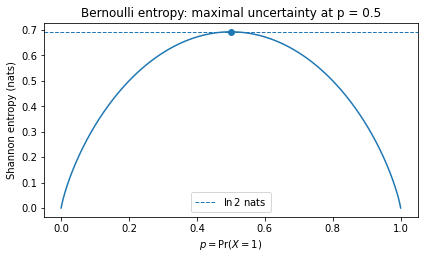

In [7]:
p_grid = np.linspace(0.0, 1.0, 501)
with np.errstate(divide='ignore', invalid='ignore'):
    H_b = -(np.where(p_grid > 0, p_grid*np.log(np.maximum(p_grid, 1e-300)), 0)
            + np.where(p_grid < 1, (1-p_grid)*np.log(np.maximum(1-p_grid, 1e-300)), 0))
plt.figure(figsize=(6.0, 3.7))
plt.plot(p_grid, H_b)
plt.axhline(np.log(2), ls='--', lw=1, label=r'$\ln 2$ nats')
plt.scatter([0.5], [np.log(2)], s=35)
plt.xlabel(r'$p=\Pr(X=1)$')
plt.ylabel('Shannon entropy (nats)')
plt.title('Bernoulli entropy: maximal uncertainty at p = 0.5')
plt.legend()
plt.tight_layout()
plt.show()
assert np.isclose(H_b[250], np.log(2))
assert np.isclose(H_b[0], 0)


## 6. Comparing distributions with cross-entropy and KL divergence 

The entropy $H(P)$ measures uncertainty **within one distribution**. Learning a probabilistic model introduces a second distribution: the source or data distribution $P$ and the model $Q$. Now it matters not only how uncertain the source is, but how much probability the model assigns to outcomes the source actually generates.

The textbook introduces KL divergence (Eq. 3.50) as

$$
\boxed{D_{\mathrm{KL}}(P\|Q)
=\mathbb E_{X\sim P}\!\left[\log\frac{P(X)}{Q(X)}\right]
=\sum_xP(x)\log\frac{P(x)}{Q(x)}.}
$$

This is an **expected log-probability ratio under $P$**; $D_{\mathrm{KL}}(P\|Q)$ is generally different from $D_{\mathrm{KL}}(Q\|P)$. For distributions with densities, the summation is replaced by an integral wherever the expression is well-defined. If $P(x)>0$ but $Q(x)=0$, the divergence is infinite: $Q$ has excluded a possible source outcome.

The related **cross-entropy** (Eq. 3.51) is

$$
\boxed{H(P,Q)=-\mathbb E_{X\sim P}[\log Q(X)].}
$$

Subtracting and adding the source's expected log probability yields

$$
\begin{aligned}
H(P,Q)
&=-\mathbb E_P[\log P(X)]+\mathbb E_P[\log P(X)-\log Q(X)]\\
&=\boxed{H(P)+D_{\mathrm{KL}}(P\|Q)}.
\end{aligned}
$$

For a **fixed** source $P$, minimizing expected cross-entropy over a family of models $Q_\theta$ is equivalent to minimizing $D_{\mathrm{KL}}(P\|Q_\theta)$, since $H(P)$ does not depend on $\theta$. With data samples from the source, empirical average negative log-likelihood estimates the model-dependent cross-entropy objective. This is the bridge from information theory to statistical learning.

### Nonnegativity is a property of the *whole expectation*, not each outcome

An individual contribution $P(x)\log[P(x)/Q(x)]$ can be negative whenever $Q(x)>P(x)$, even though

$$
\boxed{D_{\mathrm{KL}}(P\|Q)\ge0}
$$

for any valid distributions (Gibbs' inequality). There is no contradiction: some events are overestimated by the model and others underestimated, but the weighted **logarithmic** score aggregates them asymmetrically.

To see this rigorously, for positive $P(x)$ and $Q(x)$ use $-\ln t\ge1-t$ for $t>0$:

$$
\begin{aligned}
D_{\mathrm{KL}}(P\|Q)
&=-\sum_xP(x)\ln\frac{Q(x)}{P(x)}\\
&\ge\sum_xP(x)\left(1-\frac{Q(x)}{P(x)}\right)\\
&=\sum_xP(x)-\sum_xQ(x)=0.
\end{aligned}
$$

This proof makes the roles of both ingredients visible: **the logarithm inequality** establishes the direction, and **normalization** makes the lower bound zero. Normalization by itself would not justify the sign of the original log sum. Equality holds precisely when $P=Q$ on the probability space (up to null events).

Because it is not symmetric and does not generally satisfy a triangle inequality, KL divergence is **not a metric**, even though it often serves as a discrepancy measure.

In [8]:
def entropy(p):
    """Discrete Shannon entropy in nats (natural logarithm)."""
    p = np.asarray(p, dtype=float)
    mask = p > 0
    return -np.sum(p[mask] * np.log(p[mask]))

def cross_entropy(p, q):
    """Discrete cross-entropy in nats; requires q>0 wherever p>0."""
    p, q = np.asarray(p, float), np.asarray(q, float)
    if np.any((p > 0) & (q == 0)):
        return np.inf
    mask = p > 0
    return -np.sum(p[mask] * np.log(q[mask]))

def kl(p, q):
    return cross_entropy(p, q) - entropy(p)

Pdata = np.array([0.6, 0.3, 0.1])
Qmodel = np.array([0.3, 0.5, 0.2])
terms = Pdata * np.log(Pdata / Qmodel)
print('Per-outcome KL contributions (nats):', terms)
print('At least one contribution is negative?', np.any(terms < 0))
print('H(P):', entropy(Pdata))
print('H(P,Q):', cross_entropy(Pdata, Qmodel))
print('D_KL(P||Q):', kl(Pdata, Qmodel))
print('D_KL(Q||P):', kl(Qmodel, Pdata))
assert kl(Pdata,Qmodel) >= -1e-12
assert np.isclose(cross_entropy(Pdata,Qmodel), entropy(Pdata)+kl(Pdata,Qmodel))

Per-outcome KL contributions (nats): [ 0.4159 -0.1532 -0.0693]
At least one contribution is negative? True
H(P): 0.8979457248567797
H(P,Q): 1.0912716280069552
D_KL(P||Q): 0.1933259031501755
D_KL(Q||P): 0.1860980938270007


### The KL direction specifies the *reference weighting*, not which distribution is true

If we write $D_{\mathrm{KL}}(P\|Q)$, **$P$ is the distribution weighting the expectation**. The notation alone does not assert that $P$ is the genuine data-generating distribution, nor does reversing the arguments determine truth. Both arguments can represent approximate models.

Suppose the unknown real data-generating distribution is $R$. For observations $x_1,\ldots,x_N\sim R$, held-out average negative log-likelihood evaluates model $Q$ through

$$
-\frac1N\sum_{n=1}^N\log Q(x_n)\ \longrightarrow\
H(R,Q)=H(R)+D_{\mathrm{KL}}(R\|Q)
$$

under standard law-of-large-numbers assumptions and with the relevant expectations finite. The constant $H(R)$ is independent of $Q$, so differences in predictive log loss tell us which candidate has lower **forward KL from $R$**, not that the winning model is literally equal to $R$.

This answers a conceptual ambiguity: **direction is part of the mathematical objective**, not a built-in label for a 'true' and a 'false' distribution.

### Why the direction matters when the approximation family is restricted

Let $P$ be a target density, and restrict the approximation $Q_\phi$ to a single Gaussian even if $P$ is bimodal. This is the setting illustrated by *Deep Learning*, Figure 3.6.

**Forward KL** $D_{\mathrm{KL}}(P\|Q_\phi)$ integrates with respect to $P$. If a high-probability mode of $P$ receives very little density from $Q_\phi$, the penalty is large; the restricted Gaussian often **covers** both modes. For an unrestricted Gaussian fit under forward KL, minimizing expected quadratic log loss matches the target's mean and variance.

**Reverse KL** $D_{\mathrm{KL}}(Q_\phi\|P)$ integrates with respect to $Q_\phi$. Placing mass in a low-density region between modes is expensive, so the Gaussian often concentrates around **one mode** when the target modes are sufficiently well separated. This is known as mode-seeking behavior. It is a typical restricted-family phenomenon, **not a universal theorem for every target or variational family**.

For the illustrative symmetric target

$$
P(x)=\tfrac12\mathcal N(x;-4,1)+\tfrac12\mathcal N(x;4,1),
$$

forward KL is minimized over Gaussian $Q$ by $Q_F=\mathcal N(0,17)$, because the mixture has mean 0 and variance $1+4^2=17$. A Gaussian concentrated at either mode is a useful **reverse-KL candidate**, though the exact reverse-KL optimum requires optimization and depends on mode separation.

**Practical selection.** Forward KL is connected to MLE when samples come from $P$. Reverse KL is common in variational inference because one can often sample from $Q$ and evaluate an unnormalized target. Computational tractability, coverage requirements, and downstream decisions determine which objective is suitable.

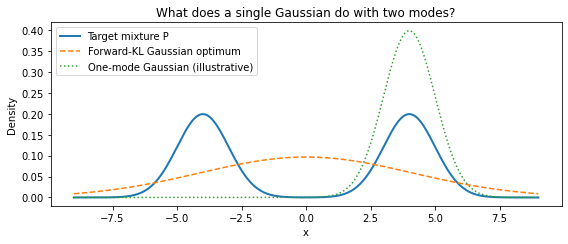

In [9]:
def normal_pdf(x, mu, sd):
    return np.exp(-0.5*((x-mu)/sd)**2) / (sd*np.sqrt(2*np.pi))

xx = np.linspace(-9,9,1300)
mixture = 0.5*normal_pdf(xx,-4,1) + 0.5*normal_pdf(xx,4,1)
forward_fit = normal_pdf(xx,0,np.sqrt(17))
mode_fit = normal_pdf(xx,4,1) # illustrative reverse-KL-like choice; not claimed optimum
plt.figure(figsize=(8,3.5))
plt.plot(xx,mixture,label='Target mixture P',lw=2)
plt.plot(xx,forward_fit,label='Forward-KL Gaussian optimum',ls='--')
plt.plot(xx,mode_fit,label='One-mode Gaussian (illustrative)',ls=':')
plt.xlabel('x');plt.ylabel('Density')
plt.title('What does a single Gaussian do with two modes?')
plt.legend()
plt.tight_layout()
plt.show()

## 7. Structured probabilistic models 

Information theory compares distributions, but in a modern machine-learning problem the distribution itself may involve hundreds or millions of random variables. A completely general joint distribution for $d$ binary variables has $2^d-1$ free probabilities. A table of that size quickly becomes infeasible.

**The idea of a structured probabilistic model is to factor a joint distribution into smaller pieces** that express local dependencies. This is both a modeling assumption (which dependencies are represented directly) and a computational advantage (how many parameters and operations are required).

### A chain: factorization and conditional independence

The textbook begins with the factorization (Eq. 3.52)

$$
\boxed{p(a,b,c)=p(a)\,p(b\mid a)\,p(c\mid b).}
$$

It corresponds to the directed chain $a\to b\to c$. The last factor expresses the assumption $p(c\mid a,b)=p(c\mid b)$, or $A\perp C\mid B$. The edge $A\to B$ states which conditional factor uses $A$ as a parent; an arrow need **not** represent a proven causal effect unless additional causal assumptions have been made.

For $d$ binary variables arranged in a directed chain, one root Bernoulli parameter plus two conditional Bernoulli parameters for each later node requires $1+2(d-1)$ scalar parameters, far fewer than $2^d-1$. The reduction comes at a price: the factorization imposes restrictions on the representable distributions.

### Directed graphical models

In a directed acyclic graph (DAG), each random variable $X_i$ has a set of parents $\mathrm{Pa}(X_i)$. The joint factorizes as (Eq. 3.53)

$$
\boxed{p(x_1,\ldots,x_d)=\prod_{i=1}^d p(x_i\mid\mathrm{Pa}(X_i)).}
$$

The factors are **normalized conditional probability distributions**, allowing straightforward joint sampling in a topological order when the conditionals can be sampled. The textbook's five-node example (Eq. 3.54) is

$$
p(a,b,c,d,e)=p(a)\,p(b\mid a)\,p(c\mid a,b)\,p(d\mid b)\,p(e\mid c).
$$

This expresses which variables directly enter each conditional factor; the graph communicates those interactions without enumerating every joint configuration.

### Undirected graphical models

An undirected model instead multiplies nonnegative **potential functions** $\phi_k$ on cliques $C_k$:

$$
\boxed{p(\mathbf x)=\frac1Z\prod_k\phi_k(\mathbf x_{C_k})},\qquad
Z=\sum_{\mathbf x}\prod_k\phi_k(\mathbf x_{C_k})
$$

for a finite discrete state space (use an integral for continuous variables). The $\phi_k$ need not individually be probability distributions, so the normalizer $Z$ is generally required. The book's five-node undirected factorization (Eq. 3.56) uses

$$
p(a,b,c,d,e)=\frac1Z\,\phi_1(a,b,c)\,\phi_2(b,d)\,\phi_3(c,e).
$$

This returns us to Part I: the *same kind of normalization difficulty* encountered with energy-based models appears naturally in undirected probabilistic models. Local conditional distributions may be easy enough for Gibbs sampling even when the global normalizing constant is hard to evaluate.

### Read conditional independence from *how* a graph connects variables

It is essential not to confuse 'there is no edge' with 'these random variables are independent'. Dependence can travel through intermediary variables, and conditioning may block or create paths. For simple directed three-variable structures:

| Structure | Factorization | Conditional implication |
|---|---|---|
| Chain $X\to Y\to Z$ | $p(x)p(y\mid x)p(z\mid y)$ | $X\perp Z\mid Y$ |
| Fork $X\leftarrow Y\to Z$ | $p(y)p(x\mid y)p(z\mid y)$ | $X\perp Z\mid Y$ |
| Collider $X\to Y\leftarrow Z$ | $p(x)p(z)p(y\mid x,z)$ | $X\perp Z$ marginally in the represented factorization, but they may become dependent after conditioning on $Y$ |

The collider case is the important warning: **conditioning does not always reduce dependence**. Graph-based separation rules (d-separation for DAGs) formalize these statements. This table is supplementary context for understanding conditional independence, not a claim that §3.14 develops full graph-separation theory.

A simple numerical check of the chain factorization uses binary conditional-probability tables below. The resulting joint is normalized, and we can directly verify that $p(c\mid a,b)$ does not depend on $a$ once $b$ is known.

In [10]:
# Binary chain A -> B -> C: construct a normalized joint by factors.
p_a = np.array([0.55, 0.45])
p_b_given_a = np.array([[0.8,0.2],[0.3,0.7]])    # rows: a; cols: b
p_c_given_b = np.array([[0.9,0.1],[0.2,0.8]])    # rows: b; cols: c
joint = np.array([[[p_a[a]*p_b_given_a[a,b]*p_c_given_b[b,c]
                    for c in range(2)] for b in range(2)] for a in range(2)])
print('Joint shape:', joint.shape, 'total probability:', joint.sum())
for b in range(2):
    conditional_c_for_each_a = joint[:,b,:] / joint[:,b,:].sum(axis=1,keepdims=True)
    print('b =',b,'; P(C | A=a, B=b) for both a values =', conditional_c_for_each_a)
    assert np.allclose(conditional_c_for_each_a[0],conditional_c_for_each_a[1])
assert np.isclose(joint.sum(),1)


Joint shape: (2, 2, 2) total probability: 1.0
b = 0 ; P(C | A=a, B=b) for both a values = [[0.9 0.1]
 [0.9 0.1]]
b = 1 ; P(C | A=a, B=b) for both a values = [[0.2 0.8]
 [0.2 0.8]]


### Why graphical structure belongs alongside information theory and MCMC

A probabilistic model needs both **a distributional description** and **a computational strategy**:

$$
\begin{array}{ccl}
\text{Model structure} &\longrightarrow& \text{factorized probabilities or potentials},\\
\text{Information theory} &\longrightarrow& \text{objectives for comparing model and data},\\
\text{MCMC / approximate inference} &\longrightarrow& \text{approximations to otherwise difficult expectations}.
\end{array}
$$

A neural network can supply the parameters of a conditional factor, potential, or energy. But choosing a highly expressive function class does not eliminate the need to normalize, sample, or optimize. This provides a direct bridge into Chapter 4, where we examine the numerical machinery underlying those computations.

---
# Part III — Numerical Computation and Optimization

*Goodfellow, Bengio, and Courville, Chapter 4, primarily 4.1–4.4*

## From mathematical objectives to reliable algorithms

By this point we can describe stochastic processes, specify probability distributions, and construct distribution-comparison objectives such as cross-entropy. The final challenge is computational: **can the required functions be evaluated and optimized reliably using finite-precision arithmetic?**

Chapter 4 of *Deep Learning* develops numerical stability, conditioning, derivatives, and constrained optimization. These topics are not independent tricks: the same matrix directions that make inversion sensitive also make optimization steep in some directions and nearly flat in others. Our main goal is to connect these geometric ideas clearly enough to distinguish what gradient descent, a curvature-based line search, Newton's method, and coordinate-wise scaling actually do.

## 8. Floating-point arithmetic: overflow, underflow, and stability

The real numbers form a continuum, but a computer stores only finitely many bit patterns. Most numbers are therefore rounded, and the representable range is bounded. Two extreme failures matter especially for likelihood-based learning:

- **Underflow:** a very small positive result becomes zero, potentially turning $\log p$ into $-\infty$ or producing division by zero.
- **Overflow:** a very large magnitude becomes infinite, potentially causing undefined expressions such as $\infty/\infty$.

The textbook's central illustration is **softmax** (Eq. 4.1), which converts logits $z_i$ into class probabilities:

$$
\mathrm{softmax}(\mathbf z)_i=\frac{e^{z_i}}{\sum_j e^{z_j}}.
$$

Direct exponentiation can overflow even when the final probabilities are perfectly well defined. But softmax is unchanged if every logit is shifted by the same constant $c$:

$$
\frac{e^{z_i-c}}{\sum_j e^{z_j-c}}=\frac{e^{z_i}}{\sum_j e^{z_j}}.
$$

Taking $c=\max_jz_j$ ensures the largest exponent is $e^0=1$ and all others are at most $1$. This avoids overflow and guarantees a nonzero denominator. **It does not guarantee every probability stays nonzero**, which is why a stable log-softmax should be computed directly:

$$
\boxed{\log\mathrm{softmax}(\mathbf z)_i
=z_i-m-\log\sum_je^{z_j-m}},\qquad m=\max_jz_j.
$$

Stable log-softmax connects Section 4.1 directly to the negative log-likelihood and cross-entropy objectives introduced in Part II.

In [11]:
logits = np.array([1000.0, 1001.0, 999.0])
with np.errstate(over='ignore', invalid='ignore', divide='ignore'):
    naive_softmax = np.exp(logits) / np.exp(logits).sum()
shifted = logits - logits.max()
stable_softmax = np.exp(shifted) / np.exp(shifted).sum()
stable_logsoftmax = shifted - np.log(np.exp(shifted).sum())
print('Naive softmax: ', naive_softmax)
print('Stable softmax:', stable_softmax)
print('Stable log-softmax:', stable_logsoftmax)
assert np.isclose(stable_softmax.sum(), 1)
assert np.all(np.isfinite(stable_logsoftmax))

# A second failure is possible even after stable softmax: a tiny numerator
# may underflow to zero before applying log. Direct log-softmax avoids it.
extreme_logits = np.array([0.0, -1000.0])
extreme_shifted = extreme_logits - extreme_logits.max()
p_extreme = np.exp(extreme_shifted) / np.exp(extreme_shifted).sum()
logp_extreme = extreme_shifted - np.log(np.exp(extreme_shifted).sum())
with np.errstate(divide='ignore'):
    # An underflowed probability yields -inf, as intended in this illustration.
    log_after_softmax = np.log(p_extreme)
print('Softmax then log:', log_after_softmax)
print('Direct log-softmax:', logp_extreme)
assert np.all(np.isfinite(logp_extreme))

Naive softmax:  [nan nan nan]
Stable softmax: [0.2447 0.6652 0.09  ]
Stable log-softmax: [-1.4076 -0.4076 -2.4076]
Softmax then log: [  0. -inf]
Direct log-softmax: [    0. -1000.]


### Algorithmic stability and mathematical conditioning are different properties

A **well-conditioned problem** changes little under small perturbations of its input. A **stable algorithm** does not amplify the rounding errors introduced during computation more than necessary. An ill-conditioned problem may defeat even a stable implementation; an unstable implementation can lose accuracy even when the underlying problem is well conditioned.

A classical cancellation example is $\sqrt{1+x}-1$ for tiny positive $x$. Algebraically it equals

$$
\frac{x}{\sqrt{1+x}+1},
$$

but the first form subtracts two nearly equal floating-point numbers, potentially discarding significant digits. Rewriting the expression preserves accuracy; it does **not** change the mathematical function being evaluated.

In [12]:
for x in [1e-8, 1e-12, 1e-16]:
    unstable = np.sqrt(1+x)-1
    stable = x/(np.sqrt(1+x)+1)
    print(f'x={x:.0e}: subtraction={unstable:.18e}, rationalized={stable:.18e}')

x=1e-08: subtraction=4.999999969612645145e-09, rationalized=4.999999987499999894e-09
x=1e-12: subtraction=5.000444502911705058e-13, rationalized=4.999999999998749839e-13
x=1e-16: subtraction=0.000000000000000000e+00, rationalized=4.999999999999999895e-17


## 9. Conditioning, matrix inversion, and eigen-directions

The book considers $f(\mathbf b)=A^{-1}\mathbf b$, where $A\in\mathbb R^{d\times d}$ is invertible. Solving $A\mathbf y=\mathbf b$ gives $\mathbf y=A^{-1}\mathbf b$. If the input changes to $\mathbf b+\delta\mathbf b$, the output changes by $\delta\mathbf y=A^{-1}\delta\mathbf b$. Some directions of the input can be magnified much more than others.

For the Euclidean norm, the general matrix condition number is

$$
\boxed{\kappa_2(A)=\lVert A\rVert_2\lVert A^{-1}\rVert_2
=\frac{\sigma_{\max}(A)}{\sigma_{\min}(A)}},
$$

where $\sigma_{\max}$ and $\sigma_{\min}$ are the largest and smallest **singular values**. For a symmetric positive-definite $A$, these are its largest and smallest eigenvalues, matching the familiar eigenvalue-ratio interpretation in the textbook (Eq. 4.2) under the appropriate assumptions. A general nonnormal diagonalizable matrix does **not** necessarily have its 2-norm condition number equal to the ratio of eigenvalue magnitudes.

For a fixed nonsingular $A$, we have the relative-error bound

$$
\frac{\lVert\delta\mathbf y\rVert_2}{\lVert\mathbf y\rVert_2}
\le\kappa_2(A)\,
\frac{\lVert\delta\mathbf b\rVert_2}{\lVert\mathbf b\rVert_2}.
$$

This is a **worst-case upper bound**, not a prediction that every perturbation is amplified by exactly $\kappa_2(A)$. It is also a statement about sensitivity of the *problem*, separate from the error introduced by a particular linear solver.

### Why one matrix can have several eigenvalues

An eigenpair $(\lambda_i,\mathbf v_i)$ satisfies $A\mathbf v_i=\lambda_i\mathbf v_i$ for some nonzero vector $\mathbf v_i$. The eigenvalue is not a unique scalar attached to the matrix as a whole; it is the factor by which the matrix scales **that particular eigenvector direction**.

For example,

$$
A=\begin{pmatrix}3&0\\0&2\end{pmatrix}
$$

satisfies $A(1,0)^\top=3(1,0)^\top$ and $A(0,1)^\top=2(0,1)^\top$. Thus $3$ and $2$ are both eigenvalues of the same matrix. The vector $(1,1)^\top$ is not an eigenvector here, because its two coordinates scale differently. In general the eigenvalues are roots of $\det(A-\lambda I)=0$, with repeated and complex eigenvalues possible.

For **symmetric** matrices, orthogonal eigenvectors provide a particularly useful coordinate system. In Part III, the Hessian is symmetric under the usual smoothness assumptions, and its eigenvectors identify principal directions of curvature. This is why the present conditioning discussion becomes directly relevant to learning-rate selection.

In [13]:
A = np.diag([1.0, 0.01])
b = np.array([1.0, 1.0])
db = np.array([0.0, 0.001])
y = np.linalg.solve(A, b)
y_perturbed = np.linalg.solve(A, b + db)
relative_input = np.linalg.norm(db)/np.linalg.norm(b)
relative_output = np.linalg.norm(y_perturbed-y)/np.linalg.norm(y)
print('Condition number:', np.linalg.cond(A))
print('Unperturbed solution:', y)
print('Perturbed solution:', y_perturbed)
print('Relative input perturbation:', relative_input)
print('Relative output perturbation:', relative_output)
print('Error-bound upper limit:', np.linalg.cond(A)*relative_input)
assert relative_output <= np.linalg.cond(A)*relative_input + 1e-12

Condition number: 100.0
Unperturbed solution: [  1. 100.]
Perturbed solution: [  1.  100.1]
Relative input perturbation: 0.0007071067811865475
Relative output perturbation: 0.0009999500037494887
Error-bound upper limit: 0.07071067811865475


## 10. Gradients and directional derivatives

Consider an objective $f:\mathbb R^d\to\mathbb R$. Its gradient at $\mathbf x$ is the vector of partial derivatives

$$
\nabla f(\mathbf x)=\begin{pmatrix}\partial f/\partial x_1\\\vdots\\\partial f/\partial x_d\end{pmatrix}\in\mathbb R^d.
$$

To ask how the objective changes **in a particular direction**, select a unit vector $\mathbf u$ and restrict the multivariable function to a line:

$$
\phi(\alpha)=f(\mathbf x+\alpha\mathbf u).
$$

Here $\alpha$ is a *scalar displacement along the line*; $\alpha=0$ identifies the original point. By the chain rule,

$$
\boxed{\left.\frac{d}{d\alpha}f(\mathbf x+\alpha\mathbf u)\right|_{\alpha=0}
=\nabla f(\mathbf x)^\top\mathbf u.}
$$

This explains the textbook's directional-derivative notation (Eq. 4.4). It is not yet a finite training step, and $\alpha$ should not automatically be confused with a chosen learning rate.

For $\lVert\mathbf u\rVert_2=1$, Cauchy–Schwarz gives

$$
\nabla f^\top\mathbf u\ge-\lVert\nabla f\rVert_2,
$$

with equality when $\mathbf u=-\nabla f/\lVert\nabla f\rVert_2$ if the gradient is nonzero. Therefore the **negative gradient is the direction of steepest local descent under the Euclidean norm**. Ordinary gradient descent uses

$$
\boxed{\mathbf x_{k+1}=\mathbf x_k-\epsilon\nabla f(\mathbf x_k).}
$$

The direction is justified by first-order calculus, but whether a **finite** step decreases the objective also depends on curvature and the step length $\epsilon$.

### Restricting a multivariable function to a line makes the derivative intuitive

Take $f(x,y)=x^2+2y^2$, with $\mathbf x=(1,2)$ and $\mathbf u=(0,1)$ (a unit vector). Along that line,

$$
\phi(\alpha)=f(1,2+\alpha)=9+8\alpha+2\alpha^2.
$$

Hence $\phi'(0)=8$. Computing the gradient directly gives $\nabla f(1,2)=(2,8)^\top$, so $\nabla f(1,2)^\top(0,1)=8$ as expected. Only the direction along $y$ is probed; the $x$ component of the gradient does not contribute to this directional derivative.

For a conventional GD step from $(1,1)$, $\nabla f(1,1)=(2,4)$; choosing $\epsilon=0.1$ gives $(0.8,0.6)$ and decreases the objective from $3$ to $1.36$. This computation illustrates a *particular successful step*, not a global theorem that every positive $\epsilon$ works.

## 11. Hessians, Taylor approximations, and curvature

A gradient describes how fast the objective changes; a **Hessian** describes how that gradient itself changes. If $f$ is twice continuously differentiable near $\mathbf x$, its Hessian is the symmetric matrix

$$
H(\mathbf x)=\left[\frac{\partial^2f}{\partial x_i\partial x_j}\right]_{i,j=1}^d\in\mathbb R^{d\times d}.
$$

For a unit direction $\mathbf u$, differentiating $\phi(\alpha)=f(\mathbf x+\alpha\mathbf u)$ again gives

$$
\boxed{\phi''(0)=\mathbf u^\top H(\mathbf x)\mathbf u.}
$$

In two dimensions this is $u_1^2f_{xx}+2u_1u_2f_{xy}+u_2^2f_{yy}$. Under an orthonormal Hessian eigenbasis $H\mathbf v_i=\lambda_i\mathbf v_i$, write $\mathbf u=\sum_i c_i\mathbf v_i$ with $\sum_i c_i^2=1$. Then

$$
\mathbf u^\top H\mathbf u=\sum_ic_i^2\lambda_i.
$$

The directional curvature is a weighted average of the eigenvalues, with weights determined by the direction. The largest and smallest Hessian eigenvalues are the largest and smallest possible second directional derivatives among unit vectors.

### The local quadratic model (textbook Eq. 4.8)

Around a current point $\mathbf x_0$ let $\mathbf g=\nabla f(\mathbf x_0)$ and $H=H(\mathbf x_0)$. With $\Delta=\mathbf x-\mathbf x_0$,

$$
\boxed{f(\mathbf x_0+\Delta)\approx f(\mathbf x_0)
+\mathbf g^\top\Delta+\tfrac12\Delta^\top H\Delta.}
$$

This second-order approximation is local. It becomes exact for a quadratic objective with constant Hessian, and it may be poor for steps that travel far from $\mathbf x_0$.

At a critical point ($\mathbf g=0$), the Hessian's eigenvalue signs provide local second-order information: positive definite implies a strict local minimum; negative definite implies a strict local maximum; indefinite implies a saddle. Semidefinite Hessians can be inconclusive without higher-order analysis.

### Deriving a curvature-based scalar step (textbook Eqs. 4.9–4.10)

Gradient descent restricts the proposed step to $\Delta=-\epsilon\mathbf g$. Substitute this into the quadratic Taylor model:

$$
\boxed{f(\mathbf x_0-\epsilon\mathbf g)
\approx f(\mathbf x_0)-\epsilon\mathbf g^\top\mathbf g
+\tfrac12\epsilon^2\mathbf g^\top H\mathbf g.}
$$

The first-order term is decreasing for $\epsilon>0$, but the second-order term accounts for curvature and can overwhelm the predicted benefit. Differentiating this scalar quadratic with respect to $\epsilon$ gives

$$
-\mathbf g^\top\mathbf g+\epsilon\mathbf g^\top H\mathbf g=0,
$$

so **if $\mathbf g^\top H\mathbf g>0$**,

$$
\boxed{\epsilon^*=\frac{\mathbf g^\top\mathbf g}{\mathbf g^\top H\mathbf g}.}
$$

This chooses the best **scalar distance along the gradient direction for the local quadratic model**. If $\mathbf g^\top H\mathbf g\le0$, this quadratic model supplies no finite positive minimizer along that ray; it does not mean that the true, nonlinear objective decreases forever.

For the exact quadratic $f(x,y)=x^2+2y^2$ at $(1,1)$, $\mathbf g=(2,4)^\top$ and $H=\mathrm{diag}(2,4)$. The actual objective along the negative gradient is $3-20\epsilon+36\epsilon^2$, minimized at $\epsilon^*=20/72\approx0.2778$.

### High curvature restricts a common learning rate

For a positive-definite Hessian, if the gradient happens to align with the eigenvector of $\lambda_{\max}$, then $\mathbf g^\top H\mathbf g=\lambda_{\max}\mathbf g^\top\mathbf g$ and

$$
\epsilon^*=\frac1{\lambda_{\max}}.
$$

This is the sense in which the textbook calls maximal eigenvalue alignment the **worst case**: the steepest curvature direction permits the smallest locally optimal step along the gradient. On an elongated quadratic bowl, a step appropriate for the steep direction can lead to very slow progress along flatter directions.

It is crucial not to conflate two different calculations:

- **Exact line search along a curvature eigen-direction:** $\epsilon^*=1/\lambda_{\max}$ for that special alignment in a positive-definite quadratic.
- **Stability of fixed-step GD for an SPD quadratic:** if $0<\epsilon<2/\lambda_{\max}$, all eigen-direction errors contract in magnitude under the iteration $\mathbf e_{k+1}=(I-\epsilon H)\mathbf e_k$.

The first is a step that minimizes a one-dimensional quadratic along a given direction; the second is an interval ensuring linear-iteration stability. They are related, but **not the same result**. The condition number $\kappa(H)=\lambda_{\max}/\lambda_{\min}$ helps explain why one fixed scalar rate struggles when curvature varies greatly across directions.

## 12. First-order descent, line search, and Newton's method: what is being optimized?

It is easy to mistake a Hessian-informed scalar learning rate for 'ordinary gradient descent' or for Newton's method. They all begin from a gradient, but they answer **different optimization subproblems**.

| Method | Step $\Delta$ | Information used | Free quantity |
|---|---|---|---|
| Standard gradient descent | $-\epsilon\mathbf g$ | Gradient | A selected/tuned scalar $\epsilon$ |
| Quadratic-model line search | $-\epsilon^*\mathbf g$ | Gradient and $\mathbf g^\top H\mathbf g$ | Scalar $\epsilon$ optimized on a fixed direction |
| Newton | $-H^{-1}\mathbf g$ | Full Hessian | Every coordinate of the step vector |

The most important point is that **standard GD does not inherently calculate or invert a Hessian**. Its direction comes from the first-order derivative. The quadratic-model line-search formula is an *optional* way to choose the scalar step using second-order information.

### Newton's method from the same Taylor expansion

Given $\mathbf g\in\mathbb R^d$ and a symmetric Hessian $H\in\mathbb R^{d\times d}$, define

$$
m(\Delta)=f(\mathbf x_0)+\mathbf g^\top\Delta+\tfrac12\Delta^\top H\Delta.
$$

Rather than restrict $\Delta$ to be parallel to $-\mathbf g$, minimize the quadratic with respect to the **whole vector**. Its gradient is $\nabla_\Delta m=\mathbf g+H\Delta$, so the stationary step satisfies $H\Delta=-\mathbf g$ and

$$
\boxed{\Delta_{\mathrm N}=-H^{-1}\mathbf g.}
$$

If $H\succ0$, this is the unique minimizer of the quadratic model. When $H$ is indefinite, the stationary step need not be a descent step, so damping, modified Hessians, or trust-region methods become important. In practice one solves the linear system rather than explicitly constructing $H^{-1}$.

In a Hessian eigenbasis, $\mathbf g=\sum_i c_i\mathbf v_i$ gives

$$
\Delta_{\mathrm N}=-\sum_i\frac{c_i}{\lambda_i}\mathbf v_i.
$$

The algorithm can **rescale and rotate** the update using full curvature information. On an exact SPD quadratic, Newton reaches the minimizer in one ideal step; for general smooth objectives its usefulness depends on local model accuracy and computational expense.

### A diagonal learning-rate matrix: a natural intermediate proposal

From these methods, a fruitful idea emerges: **why should all coordinates share one learning rate?** Let the gradient be $\mathbf g\in\mathbb R^d$ and assign a positive rate $\epsilon_i$ to each component:

$$
\boxed{\Delta=-\boldsymbol\epsilon\odot\mathbf g=-D\mathbf g},\qquad
D=\mathrm{diag}(\epsilon_1,\ldots,\epsilon_d)\succ0.
$$

This is **diagonal preconditioning**. It fits naturally between first-order GD (one scalar $\epsilon$ for all directions) and Newton (the full $H^{-1}$, which can mix directions).

To derive its relationship with the Hessian, suppose the quadratic model has a **diagonal positive-definite Hessian** $H=\mathrm{diag}(h_1,\ldots,h_d)$. The part of the local quadratic depending on $\Delta$ separates:

$$
\mathbf g^\top\Delta+\tfrac12\Delta^\top H\Delta
=\sum_i\left(g_i\Delta_i+\tfrac12h_i\Delta_i^2\right).
$$

Each term is minimized at $\Delta_i^*=-g_i/h_i$; therefore $D=\mathrm{diag}(1/h_1,\ldots,1/h_d)$ **matches Newton exactly when $H$ is diagonal**. This is a precise mathematical justification for coordinate-dependent learning rates.

For a full Hessian, off-diagonal entries $H_{ij}$ couple the coordinates; a diagonal $D$ cannot generally reproduce $H^{-1}$. Nevertheless, with $D\succ0$ and $\mathbf g\ne0$,

$$
\mathbf g^\top\Delta=-\mathbf g^\top D\mathbf g<0,
$$

so the step is a strict **local descent direction**. A finite step can still overshoot; a global scaling or line search may be necessary. If Hessian diagonal entries are zero or negative, blindly using $1/H_{ii}$ does not create a valid positive preconditioner.

This idea anticipates the broad motivation behind AdaGrad, RMSProp, and Adam: coordinates can need different effective scales. These practical algorithms generally use **gradient-history statistics**, not exact reciprocal Hessian diagonals, and Adam additionally tracks a first-moment estimate. They are not simply inexpensive implementations of Newton's method.

### The limitation becomes obvious when curvature couples coordinates

For

$$
H=\begin{pmatrix}2&1\\1&2\end{pmatrix},\qquad
\mathbf g=\begin{pmatrix}1\\0\end{pmatrix},
$$

coordinate-wise reciprocal diagonal scaling gives

$$
\Delta_{\mathrm{diag}}=
-\begin{pmatrix}1/2&0\\0&1/2\end{pmatrix}\mathbf g
=\begin{pmatrix}-1/2\\0\end{pmatrix},
$$

but full Newton solves the coupled system and produces

$$
\boxed{\Delta_{\mathrm N}=\begin{pmatrix}-2/3\\1/3\end{pmatrix}.}
$$

The second coordinate of the gradient is zero, but the second coordinate of Newton's step is not: its movement improves the **joint** quadratic model because the Hessian contains an interaction term. No purely diagonal rescaling of the given $\mathbf g$ can create that second component.

In [14]:
H = np.array([[2.0, 1.0], [1.0, 2.0]])
g = np.array([1.0, 0.0])
delta_diag = -g/np.diag(H)
delta_newton = np.linalg.solve(H, -g)
model_change = lambda delta: g@delta + 0.5*delta@H@delta
print('Diagonal update:', delta_diag, 'model improvement:', -model_change(delta_diag))
print('Newton update:  ', delta_newton, 'model improvement:', -model_change(delta_newton))
assert model_change(delta_newton) < model_change(delta_diag)

Diagonal update: [-0.5 -0. ] model improvement: 0.25
Newton update:   [-0.6667  0.3333] model improvement: 0.3333333333333333


### A controlled comparison on quadratic objectives

Let $f(\mathbf x)=\tfrac12\mathbf x^\top H\mathbf x$ for symmetric positive-definite $H$. Then $\nabla f(\mathbf x)=H\mathbf x$ and $\mathbf x^*=0$. Because the Taylor quadratic is now **exact**, this setting isolates the effect of using scalar curvature, diagonal curvature, or full curvature without confounding errors from a changing Hessian.

We compare a diagonal $H$ (coordinate axes already align with curvature eigenvectors) and a coupled $H$ (curvature directions are rotated). The naive diagonal update has no damping so its possible instability remains visible; this is deliberate, not a recommendation for practical training.

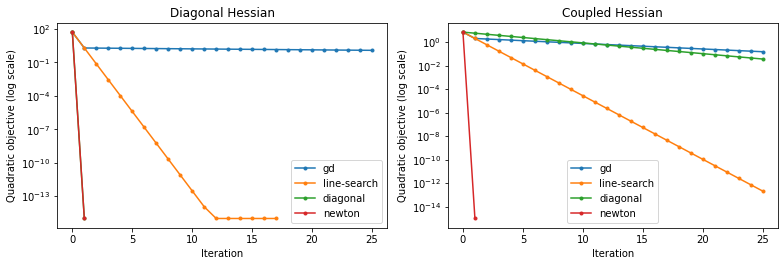

In [15]:
def quadratic_descent(H, x0, method, steps=25):
    x = np.array(x0, dtype=float)
    history = [x.copy()]
    L = np.linalg.eigvalsh(H).max()
    for _ in range(steps):
        g = H@x
        if np.linalg.norm(g) < 1e-10:
            break
        if method == 'gd':
            delta = -(1/L)*g
        elif method == 'line-search':
            delta = -(g@g)/(g@H@g)*g
        elif method == 'diagonal':
            delta = -g/np.diag(H)
        elif method == 'newton':
            delta = np.linalg.solve(H, -g)
        else:
            raise ValueError(method)
        # No backtracking: this intentionally exposes instability of an unscaled diagonal step.
        x = x+delta
        history.append(x.copy())
    return np.array(history)

H_diagonal = np.diag([1.0, 100.0])
H_coupled = np.array([[10.0, 9.0], [9.0, 10.0]]) # eigenvalues 1 and 19
x0 = np.array([2., -1.])
methods = ['gd','line-search','diagonal','newton']
fig, axes = plt.subplots(1,2,figsize=(11,3.8))
for ax, Hmat, name in zip(axes,[H_diagonal,H_coupled],['Diagonal Hessian','Coupled Hessian']):
    for method in methods:
        hist = quadratic_descent(Hmat,x0,method)
        values = np.array([0.5*x@Hmat@x for x in hist])
        ax.semilogy(range(len(values)), np.maximum(values,1e-15), marker='.', label=method)
    ax.set(title=name, xlabel='Iteration', ylabel='Quadratic objective (log scale)')
    ax.legend()
plt.tight_layout()
plt.show()

The diagonal quadratic illustrates why individual learning rates can be powerful: reciprocal curvature gives each coordinate its own appropriate scale, and the model can be solved in one step. On the coupled quadratic, the same construction fails to account for rotated curvature directions; it may oscillate or diverge without damping. The correct inference is **not** that all diagonal preconditioning is unstable, but that positivity of $D$ gives only a descent *direction*, not an unrestricted guarantee for step length one.

### Computational and geometric trade-offs

| Property | Diagonal / coordinate-wise scaling | Full Newton |
|---|---|---|
| Information stored | $O(d)$ scales | Dense Hessian $O(d^2)$ |
| Effect on interactions | Cannot represent off-diagonal rotation/coupling | Incorporates cross-coordinate curvature |
| Computational effort | Low once scales are estimated | Dense factorization typically $O(d^3)$; Hessian formation may also be expensive |
| Local descent | $-D\mathbf g$ is a descent direction if $D\succ0$ | $-H^{-1}\mathbf g$ descends if $H\succ0$, but can fail otherwise |
| Local convergence in suitable smooth settings | Generally linear with fixed diagonal preconditioning | Potentially quadratic near a nondegenerate minimizer |
| High-dimensional neural training | Gradient-statistic adaptive methods are practical | Direct dense second-order methods are usually too costly |

An exact Hessian diagonal is itself not always cheap. Moreover, diagonal scaling depends on the chosen parameter coordinates; full Newton is more faithful to the local quadratic geometry, at the price of far greater computation and nonconvexity safeguards. These considerations explain why practical optimizers trade second-order accuracy for scalable approximations.

## 13. Constrained optimization and KKT

Ordinary unconstrained descent searches all of $\mathbb R^d$. Many learning problems impose additional restrictions: parameter norms, conservation constraints, normalization, or physical feasibility. With a feasible set $\mathcal S$, the problem is $\min_{\mathbf x\in\mathcal S}f(\mathbf x)$.

The textbook first notes practical strategies such as **projection onto the feasible region**, optimization over a parameterization that automatically satisfies constraints, and gradient directions restricted to the feasible tangent space. A general alternative is to introduce multipliers and a **generalized Lagrangian**.

We follow the textbook's constraint convention (Eq. 4.14) exactly:

$$
\begin{aligned}
\min_{\mathbf x\in\mathbb R^d}\quad &f(\mathbf x)\\
\text{subject to}\quad&g_i(\mathbf x)=0,&& i=1,\ldots,m,\\
&h_j(\mathbf x)\le0,&& j=1,\ldots,r.
\end{aligned}
$$

Define

$$
\boxed{\mathcal L(\mathbf x,\boldsymbol\lambda,\boldsymbol\alpha)
=f(\mathbf x)+\sum_{i=1}^m\lambda_i g_i(\mathbf x)
+\sum_{j=1}^r\alpha_j h_j(\mathbf x).}
$$

Equality multipliers $\lambda_i\in\mathbb R$ are unrestricted; inequality multipliers $\alpha_j\ge0$ use the sign convention appropriate to $h_j\le0$.

### The textbook's minimax interpretation (Eqs. 4.15–4.18)

Before deriving local conditions, it is illuminating to look at

$$
\min_{\mathbf x}\sup_{\boldsymbol\lambda\in\mathbb R^m,\,\boldsymbol\alpha\ge0}
\mathcal L(\mathbf x,\boldsymbol\lambda,\boldsymbol\alpha).
$$

For a feasible $\mathbf x$, every equality contribution is zero and every $h_j(\mathbf x)\le0$ makes the maximizing $\alpha_j$ choose zero, so the inner supremum equals $f(\mathbf x)$. For an infeasible $\mathbf x$, a violated equality permits an unrestricted multiplier to send the value to $+\infty$, or a positive inequality violation permits $\alpha_j\to+\infty$. Thus the inner supremum acts like an **indicator of feasibility**: $f(\mathbf x)$ on the feasible set and $+\infty$ outside it.

This explains the generalized Lagrangian more accurately than the statement 'we just minimize a new unconstrained function'. The order of the **min** and **sup** operations matters; it is not valid to interchange them without additional conditions.

### KKT conditions: stationarity together with feasibility and multiplier structure

For differentiable constraints, the standard KKT conditions at a regular local minimizer are

$$
\begin{aligned}
\text{Stationarity: }&\nabla f(\mathbf x^*)+\sum_i\lambda_i^*\nabla g_i(\mathbf x^*)+\sum_j\alpha_j^*\nabla h_j(\mathbf x^*)=0,\\
\text{Primal feasibility: }&g_i(\mathbf x^*)=0,\quad h_j(\mathbf x^*)\le0,\\
\text{Dual feasibility: }&\alpha_j^*\ge0,\\
\text{Complementary slackness: }&\alpha_j^*h_j(\mathbf x^*)=0.
\end{aligned}
$$

**Why this is more subtle than unconstrained optimization.** A constrained minimum may have $\nabla f(\mathbf x^*)\ne0$: the gradient can point toward an **infeasible** direction of improvement. Constraint gradients then balance it. We do **not** generally set the derivative of the Lagrangian with respect to every inequality multiplier to zero: an inactive inequality has $h_j<0$ and must have $\alpha_j=0$; an active inequality has $h_j=0$ and may have a positive **or zero** multiplier. Equality constraints must hold even if their multipliers happen to be zero.

Under appropriate **constraint qualifications**, KKT is necessary for a regular local optimum. For convex $f$ and convex $h_j$, with affine equality constraints $g_i$, any feasible point with multipliers satisfying KKT is a **global minimizer**; standard regularity assumptions help guarantee the existence of multipliers. Outside convex settings, a KKT point need not be a minimum.

The three analytic examples below isolate inequality multipliers, equality multipliers, and their simultaneous action.

### Inequality constraint: the boundary can be optimal with a nonzero objective gradient

Minimize $(x-3)^2$ subject to $x\le2$. Using $h(x)=x-2$ and $\alpha\ge0$,

$$
\mathcal L(x,\alpha)=(x-3)^2+\alpha(x-2),\qquad
\frac{\partial\mathcal L}{\partial x}=2(x-3)+\alpha.
$$

The unconstrained optimum $x=3$ is infeasible. The feasible point closest to $3$ is $x^*=2$, giving $\alpha^*=2$. It satisfies all KKT conditions, and convexity makes it globally optimal.

$$
\boxed{x^*=2,\qquad\alpha^*=2,\qquad f'(2)=-2\ne0.}
$$

Here $f'(2)$ does not vanish; the active constraint supplies the balancing term $\alpha^*h'(2)=2$. If the upper bound is $b<3$, the optimal value is $V(b)=(b-3)^2$ and $V'(2)=-2=-\alpha^*$. This gives the multiplier a **sensitivity interpretation**: it records the first-order change in optimal value from relaxing the bound, under suitable regularity.

### Equality constraint: the multiplier can be nonzero even though there is no inequality

Consider minimizing the squared distance to the origin subject to staying on the line $x+y=4$:

$$
\min_{x,y}\ x^2+y^2\quad\text{such that}\quad g(x,y)=x+y-4=0.
$$

With unrestricted equality multiplier $\lambda$,

$$
\mathcal L=x^2+y^2+\lambda(x+y-4),\qquad
2x+\lambda=0,\quad 2y+\lambda=0.
$$

Stationarity implies $x=y$. Feasibility then gives $x^*=y^*=2$ and $\lambda^*=-4$:

$$
\boxed{(x^*,y^*)=(2,2),\qquad\lambda^*=-4.}
$$

The unconstrained objective gradient at the solution is $(4,4)^\top$, not zero. Its cancellation by $-4(1,1)^\top$ expresses that the optimum is **stationary along the feasible line**, even though descending directly toward the origin would violate the equality. Geometrically, $\nabla f$ is normal to the feasible line at the constrained optimum.

### Mixed constraints: zero and nonzero multipliers are both informative

The initial example combining both kinds of constraints was

$$
\min_{x,y}(x-3)^2+(y-2)^2,\qquad x+y-4=0,\quad x-2\le0.
$$

The closest point on the **equality line alone** is $(2.5,1.5)$, but it violates the upper bound. The feasible optimum is $(2,2)$ and the KKT multipliers are $\lambda^*=0$ and $\alpha^*=2$. The equality was enforced despite having a zero multiplier. **A multiplier of zero does not mean its constraint is discarded.**

To exhibit a setting in which **both** constraint gradients are needed, adjust the objective:

$$
\min_{x,y}(x-4)^2+(y-3)^2,
\quad g(x,y)=x+y-4=0,
\quad h(x,y)=x-2\le0.
$$

The equality-only optimum $(2.5,1.5)$ is infeasible; the mixed optimum is again $(2,2)$. At this point,

$$
\begin{aligned}
2(x-4)+\lambda+\alpha&=0,\\
2(y-3)+\lambda&=0,\\
x+y-4&=0,\\
x-2&=0.
\end{aligned}
$$

Solving gives $\lambda^*=2$, $\alpha^*=2$ and

$$
\underbrace{(-4,-2)}_{\nabla f}
+\underbrace{2(1,1)}_{\lambda\nabla g}
+\underbrace{2(1,0)}_{\alpha\nabla h}=(0,0).
$$

Both examples are convex, so satisfying the KKT conditions identifies their global minimizers. Together they show why it is necessary to check **primal feasibility, dual feasibility, stationarity, and complementary slackness separately**, instead of merely setting the gradient of a modified objective to zero.

In [16]:
# Numerically verify two KKT certificates with equality and inequality constraints.
# residuals: stationarity, equality feasibility, inequality feasibility,
#            nonnegative inequality multiplier, complementary slackness.

def validate_kkt(grad_f, grad_g, grad_h, gval, hval, lam, alpha, atol=1e-10):
    stationarity = np.asarray(grad_f) + lam*np.asarray(grad_g) + alpha*np.asarray(grad_h)
    return (np.allclose(stationarity, 0, atol=atol)
            and abs(gval) <= atol and hval <= atol
            and alpha >= -atol and abs(alpha*hval) <= atol)

# Mixed-constraint example: f=(x-3)^2+(y-2)^2, x+y=4, x<=2.
x,y,lam,alpha = 2.,2.,0.,2.
print('Original mixed example:', validate_kkt(
    [2*(x-3),2*(y-2)], [1,1], [1,0], x+y-4, x-2, lam, alpha))

# Variant with both multipliers nonzero.
x,y,lam,alpha = 2.,2.,2.,2.
print('Both-nonzero-multipliers variant:', validate_kkt(
    [2*(x-4),2*(y-3)], [1,1], [1,0], x+y-4, x-2, lam, alpha))

Original mixed example: True
Both-nonzero-multipliers variant: True


### The geometry of the equality-only optimum

For $f(x,y)=x^2+y^2$ subject to $x+y=4$, the contours of $f$ are circles around the origin, while the feasible set is a straight line. The smallest contour touching that line has a tangent parallel to the line, so its normal (the gradient of $f$) aligns with the normal of the constraint $\nabla g=(1,1)$. The KKT multiplier records the proportionality factor. The following plot makes this stationarity-along-a-feasible-set picture visible.

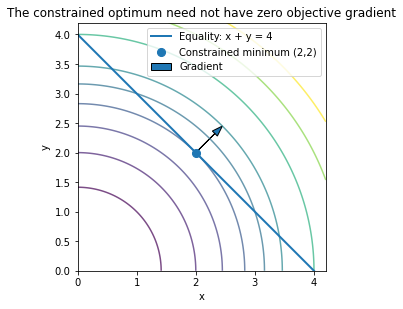

In [17]:
gx = np.linspace(0,4.2,190)
gy = np.linspace(0,4.2,190)
GX,GY = np.meshgrid(gx,gy)
F = GX**2 + GY**2
plt.figure(figsize=(5.7,4.4))
plt.contour(GX,GY,F,levels=[2,4,6,8,10,12,16,20,24], alpha=0.7)
t = np.linspace(0,4,150)
plt.plot(t,4-t,lw=2,label='Equality: x + y = 4')
plt.scatter([2],[2],s=65,zorder=4,label='Constrained minimum (2,2)')
plt.arrow(2,2,.45,.45,head_width=.12,length_includes_head=True,label='Gradient')
plt.xlabel('x');plt.ylabel('y')
ax = plt.gca()
ax.set_aspect('equal', adjustable='box')
ax.set_xlim(0,4.2);ax.set_ylim(0,4.2)
plt.title('The constrained optimum need not have zero objective gradient')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

---
# Synthesis: how the three parts fit together

Stochastic processes, information theory, probabilistic structure, and numerical optimization address different parts of the same mathematical modeling pipeline.

**1. A specified distribution and a usable sampler are different objects.** Markov chains describe time evolution, while MCMC constructs transitions targeting a distribution that may be known only up to normalization. Stationarity alone is insufficient to establish finite-time reliability; mixing and autocorrelation matter. Learned generative models can sample quickly once trained, but they replace the specified target with a learned approximation unless further correction is used.

**2. An uncertain event, an uncertain distribution, and a model discrepancy are different concepts.** The three basic information desiderata in the textbook lead to self-information $I(x)=-\log P(x)$; averaging gives entropy $H(P)$; introducing another distribution gives KL divergence and cross-entropy. KL's direction identifies the reference expectation, not which argument is 'true'. Nonnegativity is a global inequality about the expectation, not the sign of each contribution.

**3. Representing high-dimensional probability requires structure.** Directed graphs factorize into conditional probability distributions; undirected graphs factorize into potentials that may need a partition function. The latter connects naturally to energy-based models and difficult expectations. Neural networks can provide flexible factors, but flexibility does not eliminate inference or normalization difficulties.

**4. Numerical algorithms obey the geometry of the objective.** Gradient descent chooses a first-order direction. A curvature-based scalar line search improves only its step length. Newton optimizes the full quadratic-model step by using the Hessian. The proposed coordinate-wise learning-rate matrix is a principled diagonal approximation that works exactly for diagonal SPD curvature but cannot fully handle coupled directions. Condition numbers quantify the resulting geometric difficulty.

**5. Constraints change what 'stationary' means.** At a constrained minimum the objective gradient may be nonzero because unconstrained descent is infeasible. Equality and inequality gradients combine through multipliers; KKT enforces the necessary signs, feasibility, and complementary-slackness logic.
